# π0.5, step by step 🧭
### One model that first *says* what to do next, then *does* it, and learns from text as well as from robots

**Model:** `Pi05Policy` (`src/Halo_VLA/pi_family/pi05.py`) · **papers:** Physical Intelligence, *π0.5: a Vision-Language-Action Model with
Open-World Generalization*, 2025 ([arXiv:2504.16054](https://arxiv.org/abs/2504.16054)) · D. Driess et al., *Knowledge Insulating
Vision-Language-Action Models*, 2025 ([arXiv:2505.23705](https://arxiv.org/abs/2505.23705)) · K. Pertsch et al., *FAST: Efficient
Action Tokenization for VLAs*, 2025 ([arXiv:2501.09747](https://arxiv.org/abs/2501.09747))

π0 could follow a short instruction in scenes like its training data. π0.5 was built to clean *new* homes, which needs two things π0 lacked:
**semantic reasoning about what to do next** in a long task, and **knowledge that does not come from robot data**. Its recipe:

| change vs π0 | why | step |
|---|---|---|
| robot **state as text tokens** (discretised) | everything the VLM reads is text or images, as in pre-training | 1 |
| **FAST action tokens** (DCT + BPE) | lets the VLM itself learn actions with a plain next-token loss | 2 |
| **subtask prediction** ("go to red") | *hierarchical inference*: decide the next step in words, then act | 3, 7 |
| **adaRMSNorm** time conditioning | τ modulates every norm of the action expert (replaces π0's action-time MLP) | 4 |
| loss = CE(text + FAST) + **α = 10** · flow | one model, discrete and continuous heads, trained together | 5 |
| **knowledge insulation** (π0.5-KI) | stop the expert's gradient from damaging the VLM | 5, 9 |
| **co-training** on web data, many robots, verbal instructions | open-world generalisation (the toy only mixes two task families) | 0 |

| | published π0.5 | this notebook |
|---|---|---|
| backbone | PaliGemma 3B | width 64, 2 layers |
| state | 256 bins per dimension, as text | 32 bins |
| action expert | 300M, adaRMSNorm, flow matching | width 48, adaRMSNorm |
| text targets | subtasks, FAST tokens, captions, VQA, ... | subtasks + FAST tokens |

> Runs on a laptop CPU in about 8 minutes (VQA pre-training and two robot trainings). Read `pi0_step_by_step.ipynb` first: masks, the mixture of transformers
> and flow matching are explained there and reused here unchanged.

## Step 0: Setup and a two-stage task

The point world now also has **`"collect red then blue"`**: go to the first object (it disappears when reached), then to the second.
The demonstrations are annotated per step with the **subtask** the demonstrator was doing (`"go to red"`, then `"go to blue"`), like
π0.5's human segment annotations. We mix it with the one-stage `"go to <colour>"` task.

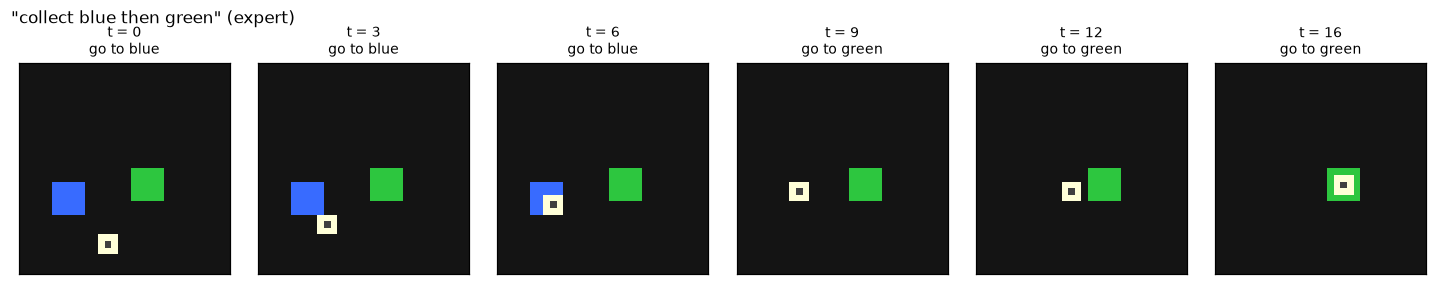

In [1]:
import time, copy, numpy as np, torch
import matplotlib.pyplot as plt
import pi_kit
pi_kit.setup_paths()
from pi_kit import plots, diagrams as dg

from pi_family import Pi05Config, Pi05Policy, PiTrainer, FastActionTokenizer, StateDiscretizer, AdaRMSNorm
from pi_family.masks import split_prefix_suffix_mask
from pi_family.pretraining import VQAPretrainer
from pi_family.toy import PointWorld, DemoGenerator, ChunkDataset, ClosedLoopEvaluator, make_scenarios

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld()
gen = DemoGenerator(world)
episodes = gen.dataset(["reach", "collect"], 4000, np.random.default_rng(0))
config = Pi05Config()
data = ChunkDataset(episodes, world, config.chunk_size)
collect_ep = next(e for e in episodes if e.kind == "collect")
plots.show_episode(data, collect_ep, steps=np.linspace(0, collect_ep.active_steps, 6).astype(int))

### 🖼️ Diagram: hierarchical inference with one model
The same network runs twice per control step: first as a language model that writes the **subtask**, then, with the subtask in its prompt, as a
VLA whose action expert produces the chunk.

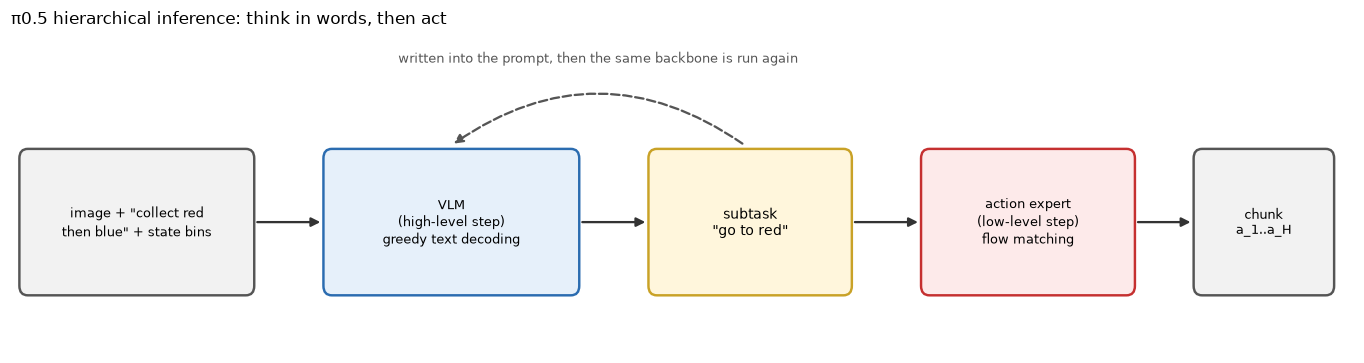

In [2]:
dg.fig_pi05_hierarchy()

## Step 1: The robot state becomes text

π0 projected `q_t` with a linear layer into the action expert. π0.5 instead **discretises** every (normalised) dimension into bins and writes
the bin indices as tokens in the prompt: the VLM only ever reads images and tokens, as in its pre-training. (π0.7 goes back to a linear
projection, but into the backbone: see the next notebook.)

In [3]:
disc = StateDiscretizer(config.state_bins)
q = torch.tensor([[0.13, 0.77]])
print("state", q.tolist(), "-> bins", disc.encode(q).tolist(), "-> decoded", disc.decode(disc.encode(q)).round(decimals=3).tolist())
print(f"resolution: 1/{config.state_bins} = {1 / config.state_bins:.3f} of the workspace (π0.5: 256 bins)")

state [[0.12999999523162842, 0.7699999809265137]] -> bins [[4, 24]] -> decoded [[0.14100000262260437, 0.765999972820282]]
resolution: 1/32 = 0.031 of the workspace (π0.5: 256 bins)


## Step 2: FAST, actions as tokens

To train the VLM *itself* on actions with next-token prediction, a chunk must become a short sequence of discrete tokens. Naive per-step
binning gives `H × action_dim` highly correlated tokens. **FAST** compresses first:

1. **DCT** along time, per dimension: a smooth chunk puts nearly all energy in a few low-frequency coefficients;
2. **quantise** `round(γ · coefficient)`: most high-frequency coefficients become 0;
3. flatten **frequency-major** (all dims of frequency 0, then 1, ...), so the zeros form long runs at the end;
4. **BPE**: merge frequent pairs (`0 0`, ...) into single tokens.

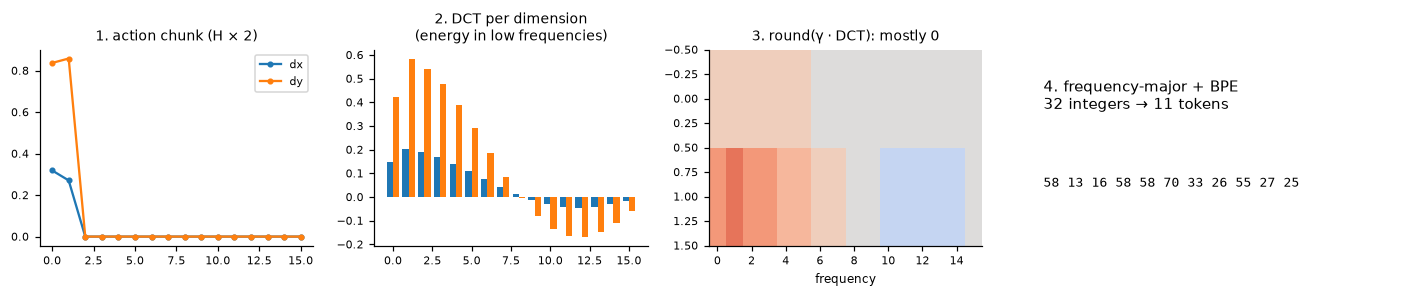

32 numbers per chunk -> 13.0 FAST tokens on average (max 23)
reconstruction MSE 0.0050  (actions have variance 0.186)


In [4]:
fit_chunks = data.sample(1000, np.random.default_rng(1)).actions
fast = FastActionTokenizer(config.chunk_size, config.action_dim, config.fast_scale, config.fast_max_coefficient,
                           config.fast_bpe_merges).fit(fit_chunks[:500])
chunk = fit_chunks[3]
dg.fig_fast_tokenizer(chunk.numpy(), (fast.dct @ chunk).numpy(), fast.quantize(chunk).numpy(), fast.encode(chunk))
held_out = fit_chunks[500:]
lengths = np.array([len(fast.encode(c)) for c in held_out])
recon = torch.stack([fast.decode(fast.encode(c)) for c in held_out])
print(f"{config.chunk_size * config.action_dim} numbers per chunk -> {lengths.mean():.1f} FAST tokens on average (max {lengths.max()})")
print(f"reconstruction MSE {(recon - held_out).pow(2).mean():.4f}  (actions have variance {held_out.var():.3f})")

The scale γ trades sequence length against precision; the FAST paper picks it so reconstruction error is negligible for control.

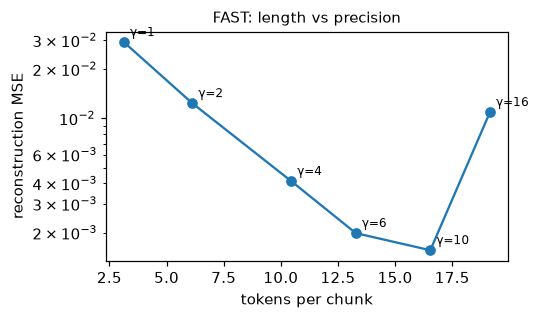

In [5]:
rows = []
for gamma in (1, 2, 4, 6, 10, 16):
    tok = FastActionTokenizer(config.chunk_size, 2, gamma, 24, config.fast_bpe_merges).fit(fit_chunks[:300])
    lens = [len(tok.encode(c)) for c in held_out[:200]]
    err = torch.stack([tok.decode(tok.encode(c)) - c for c in held_out[:200]]).pow(2).mean().item()
    rows.append((gamma, np.mean(lens), err))
fig, ax = plt.subplots(figsize=(5, 3)); g, l, e = zip(*rows)
ax.plot(l, e, "o-"); [ax.annotate(f"γ={x}", (li, ei), fontsize=8, xytext=(4, 4), textcoords="offset points") for x, li, ei in rows]
ax.set_xlabel("tokens per chunk"); ax.set_ylabel("reconstruction MSE"); ax.set_yscale("log"); ax.set_title("FAST: length vs precision", fontsize=10)
plt.tight_layout(); plt.show()

## Step 3: The full sequence and its mask

```
[ image  <bos> task <sep> state bins <sep> ]  [ subtask words <eos> ]  [ <boa> FAST … <eoa> ]  [ a_1 … a_H ]
  one bidirectional block                       causal, CE target        causal, CE target       action expert
```

Two details matter:

* the subtask and FAST tokens are **causal**: they are predicted left to right (teacher forcing during training);
* the action expert **may read the subtask** but **may not read the FAST tokens** - they encode the very chunk it must produce, so attending
  them would let it copy the answer during training and then fail at run time, when they are not there.

vocabulary: 159 ids = 54 words + 32 state bins + 73 FAST tokens
example 0 text: <bos> collect blue then red <sep> <s11> <s10> <sep> go to blue <eos> <boa> <f18> <f24> <f6> <f18> <f5> <f11> <f16> <f14> <f43> <f14> <f27> <f38> <f28> <f30> <f66> <f31> <f26> <f28> <f12> <eoa>


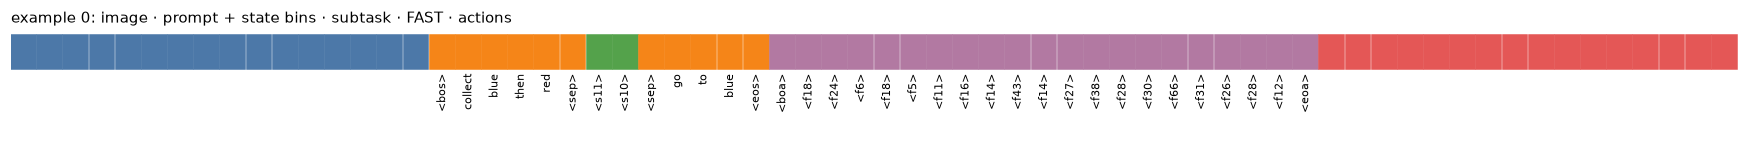

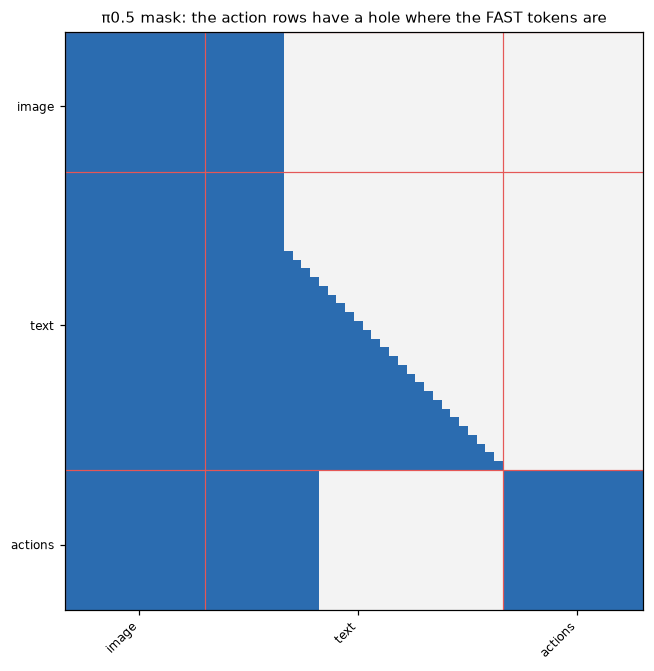

In [6]:
model = Pi05Policy(config, fast)
batch = data.sample(6, np.random.default_rng(2))
prefix = model.build_prefix(batch, train=True)
suffix = model.build_suffix(batch, torch.randn(6, config.chunk_size, 2), torch.rand(6, config.chunk_size))
print("vocabulary:", model.vocab.size, "ids =", model.vocab.state_offset, "words +", config.state_bins, "state bins +", fast.vocab_size, "FAST tokens")
print("example 0 text:", model.vocab.decode(prefix.ids[0][prefix.ids[0] >= 0].tolist()))
plots.plot_token_layout(prefix, config.chunk_size, vocab=model.vocab, title="example 0: image · prompt + state bins · subtask · FAST · actions")
pm, sm = split_prefix_suffix_mask(prefix.ar, prefix.valid, prefix.action_visible, suffix.ar)
plots.plot_attention_mask(pm, sm, prefix, title="π0.5 mask: the action rows have a hole where the FAST tokens are")

## Step 4: Adaptive RMSNorm carries the flow time

π0 mixed τ into each action token with an MLP. π0.5's action expert instead lets τ **modulate every normalisation**:

$$\mathrm{adaRMS}(x, c) = \frac{x}{\mathrm{rms}(x)}\,(1 + \mathrm{scale}(c)) + \mathrm{shift}(c), \qquad x \leftarrow x + \mathrm{gate}(c)\cdot \mathrm{branch}(\ldots)$$

with `c = MLP(φ(τ))`. The modulation is **zero-initialised** (adaLN-Zero, as in DiT): at initialisation every expert layer is the identity,
which makes the freshly added expert harmless to start from. The conditioning is given *per action token*, which π0.7's real-time chunking
needs (different τ for different tokens of the same chunk).

In [7]:
norm = model.transformer.expert[0].attn_norm
x = torch.randn(2, config.chunk_size, config.expert_width)
cond = model.time_cond(torch.rand(2, config.chunk_size))
y, gate = norm(x, cond)
print(type(norm).__name__, "| gate at init:", float(gate.abs().max()), "| output = plain RMSNorm at init:",
      torch.allclose(y, x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + 1e-6), atol=1e-5))

AdaRMSNorm | gate at init: 0.0 | output = plain RMSNorm at init: True


/var/folders/_q/55b37d8s6sq3xq4j5ll92c400000gn/T/ipykernel_33767/3639799341.py:5: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:823.)
  print(type(norm).__name__, "| gate at init:", float(gate.abs().max()), "| output = plain RMSNorm at init:",


## Step 5: The loss, and knowledge insulation

$$\mathcal{L} = \underbrace{\mathrm{CE}(\text{subtask}) + \mathrm{CE}(\text{FAST})}_{\text{backbone, next-token}} \;+\; \alpha\,\underbrace{\big\|v_\theta(x_\tau,\tau) - (\varepsilon - a)\big\|^2}_{\text{action expert}}, \qquad \alpha = 10$$

The π0.5-KI paper observed that the flow-matching gradient of a *freshly initialised* action expert is a noisy, large signal that degrades the
pre-trained VLM (slower training, worse language following). **Knowledge insulation** blocks it: the expert reads the backbone's keys/values
through `detach()`. The backbone still learns about actions - from the FAST cross-entropy - and the expert learns to read those
representations.

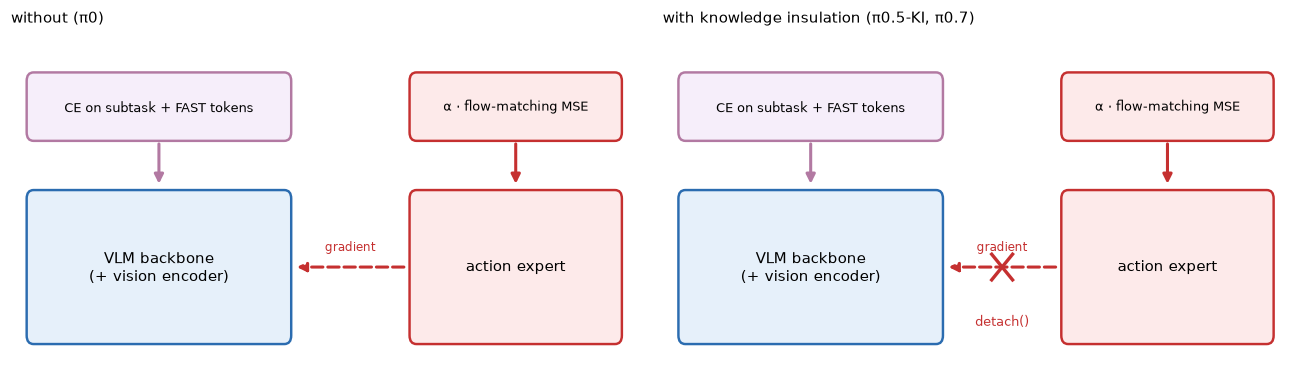

knowledge insulation False: |∇ backbone| from flow loss = 0.0005, from text loss = 0.4679
knowledge insulation True : |∇ backbone| from flow loss = 0.0000, from text loss = 0.4679


In [8]:
dg.fig_knowledge_insulation()

def backbone_grad(model, batch, loss_name):
    model.zero_grad()
    getattr(model.compute_loss(batch), loss_name).backward()
    return sum(p.grad.norm().item() ** 2 for p in model.transformer.backbone.parameters() if p.grad is not None) ** 0.5

probe = copy.deepcopy(model)
for m in probe.modules():                       # wake the zero-initialised gates so gradients can flow at all
    if isinstance(m, AdaRMSNorm):
        torch.nn.init.normal_(m.modulation.weight, std=0.1)
big = data.sample(32, np.random.default_rng(4))
for ki in (False, True):
    probe.config.knowledge_insulation = ki
    print(f"knowledge insulation {str(ki):5s}: |∇ backbone| from flow loss = {backbone_grad(probe, big, 'flow'):.4f},"
          f" from text loss = {backbone_grad(probe, big, 'text'):.4f}")

## Step 6: Train (stage 0: VQA, then robot data)

As in the π0 notebook, the toy backbone first gets a short VLM pre-training on visual question answering (π0.5 starts from PaliGemma and
keeps co-training on web data throughout). The main model then follows the original π0.5 paper (no insulation); Step 9 trains the
insulated variant from the same pre-trained snapshot.

VQA pre-training: 24 s, answer-token accuracy 0.93


step   750  loss 3.0697  (text_acc 0.406, flow 0.107, text 1.997)


step  1500  loss 1.9332  (text_acc 0.560, flow 0.053, text 1.400)


step  2250  loss 1.6678  (text_acc 0.620, flow 0.045, text 1.219)


step  3000  loss 1.3439  (text_acc 0.625, flow 0.026, text 1.081)
trained in 132 s


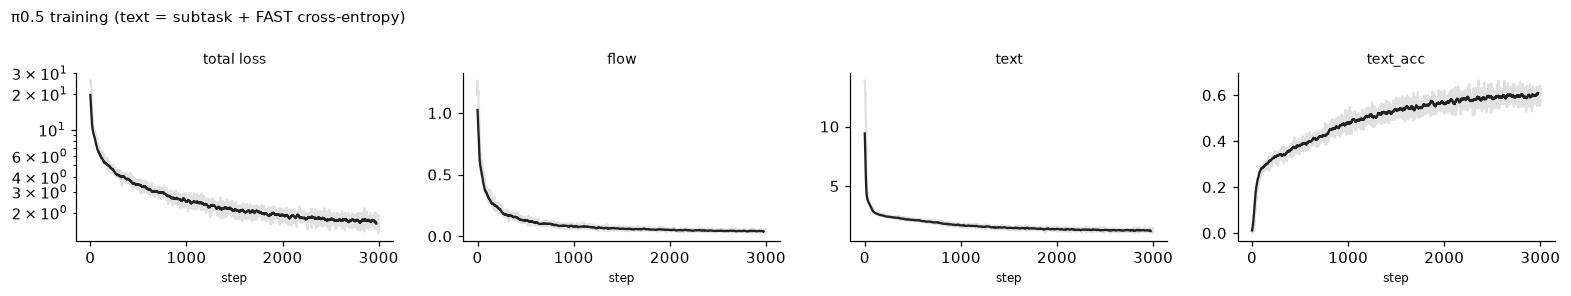

In [9]:
torch.manual_seed(0)
model = Pi05Policy(config, fast)
vqa = VQAPretrainer(model, world)
vqa.fit(1500)
print(f"VQA pre-training: {vqa.history.seconds:.0f} s, answer-token accuracy {np.mean(vqa.history.accuracy[-50:]):.2f}")
pretrained = copy.deepcopy(model)
history = PiTrainer(model, data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000, log_every=3000 // 4)
print(f"trained in {history.seconds:.0f} s")
plots.plot_loss(history, keys=("flow", "text", "text_acc"), title="π0.5 training (text = subtask + FAST cross-entropy)")

## Step 7: Hierarchical inference

**High level:** greedy-decode the subtask from image + task + state. **Low level:** put it in the prompt and sample the chunk. We check the
subtask accuracy on unseen frames, then run the two-stage task in closed loop, re-deciding the subtask at every re-plan.

subtask accuracy on unseen collect frames: 0.99


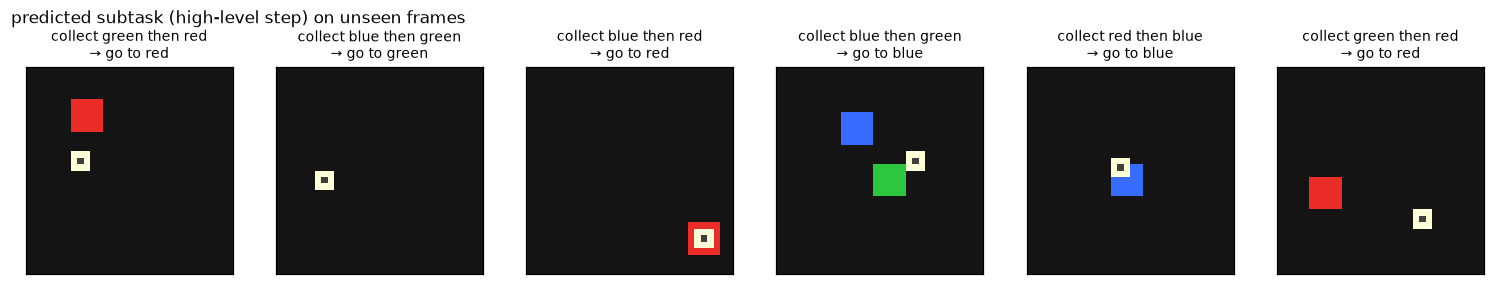

In [10]:
test = ChunkDataset(gen.dataset(["collect"], 300, np.random.default_rng(99)), world, config.chunk_size)
tb = test.sample(256, np.random.default_rng(5))
pred = model.predict_subtask(tb)
acc = np.mean([p == t for p, t in zip(pred, tb.subtask)])
print(f"subtask accuracy on unseen collect frames: {acc:.2f}")
show = tb.replace(subtask=pred)
plots.show_batch(show, n=6, show_chunk=False, title="predicted subtask (high-level step) on unseen frames")

collect, model decides the subtask: {'success': 0.984, 'wrong_first': 0.016, 'steps': 25.0, 'path': 1.069}
collect, coach gives the subtask   : {'success': 0.953, 'wrong_first': 0.0, 'steps': 24.9, 'path': 1.087}
reach,   model decides the subtask: {'success': 1.0, 'wrong_first': 0.031, 'steps': 11.0, 'path': 0.464}


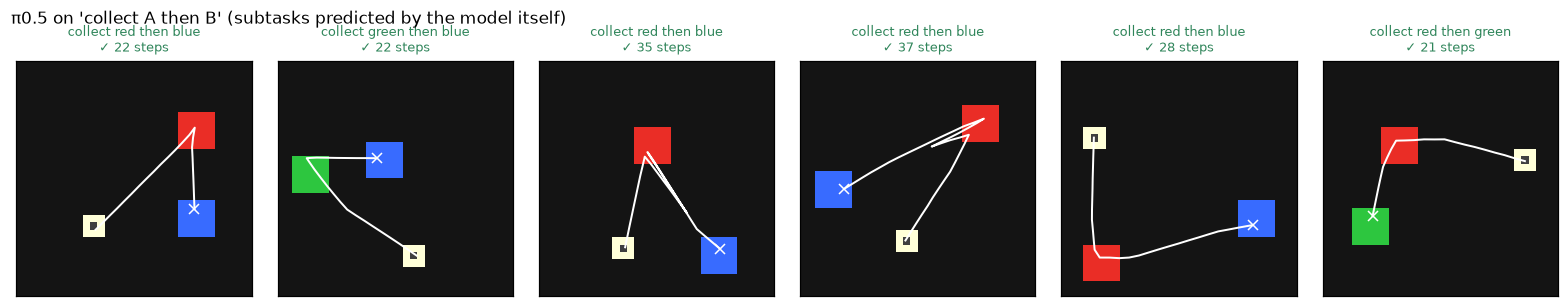

In [11]:
evaluator = ClosedLoopEvaluator(world, config.chunk_size, exec_horizon=8, max_steps=70)
collect = make_scenarios(gen, "collect", 64, seed=123)
reach = make_scenarios(gen, "reach", 64, seed=321)
r_hier = evaluator.run(lambda b, c: model.act(b), collect)
r_reach = evaluator.run(lambda b, c: model.act(b), reach)
r_oracle = evaluator.run(lambda b, c: model.sample_actions(b), collect)       # subtask from a human "coach"
print("collect, model decides the subtask:", r_hier.summary())
print("collect, coach gives the subtask   :", r_oracle.summary())
print("reach,   model decides the subtask:", r_reach.summary())
plots.plot_rollouts(r_hier, collect, world, title="π0.5 on 'collect A then B' (subtasks predicted by the model itself)")

### Verbal coaching 🔬: when does the low level obey the subtask?

π0.5 (and π0.7) can be *coached*: a person types the next subtask instead of the high-level policy. Whether the low level obeys depends on whether the subtask
carries information the rest of the prompt does not. Here we deliberately **contradict** the task: the task says "collect A then B", the coach says
"go to the other object" first.

In [12]:
def coach_other(b, committed):
    wrong = [f"go to {[c for c in s.scene.objects if c != s.targets[0]][0]}" for s in collect]
    return model.sample_actions(b.replace(subtask=wrong))

r_coach = evaluator.run(coach_other, collect)
went = np.mean([r == [c for c in s.scene.objects if c != s.targets[0]][0] for r, s in zip(r_coach.reached, collect)])
print(f"coached to the other object first: robot touched it first in {went:.0%} of scenes")

coached to the other object first: robot touched it first in 0% of scenes


**Reading the result.** In this toy the subtask is *redundant*: "go to red" is always the first item of "collect red then blue", and after red has
been collected the picture itself shows what is left. The low level therefore learned to rely on the task text and the scene, and a contradicting coach is
ignored. In the real π0.5 the overall task ("clean the kitchen") does **not** determine the next move, so the subtask is the only place the information
lives and the model follows it (the paper demonstrates language following with out-of-distribution instructions). To see the effect here you would need
tasks whose subtask is not a function of the task text, for example a random order of two goals.

## Step 8: Two ways to act from one model

The same trained network can output actions **discretely** (decode FAST tokens autoregressively, like π0-FAST and π0.5's pre-training
stage) or **continuously** (the flow-matching expert). π0.5 uses the discrete head for training the backbone and the expert at run time:
FAST decoding needs one full backbone pass *per token*; the expert needs one backbone pass plus 10 small expert passes.

In [13]:
small = tb.replace(images=tb.images[:64], state=tb.state[:64], actions=tb.actions[:64], task=tb.task[:64], subtask=tb.subtask[:64])
t0 = time.perf_counter(); a_fast = model.decode_fast_actions(small); t_fast = time.perf_counter() - t0
t0 = time.perf_counter(); a_flow = model.sample_actions(small); t_flow = time.perf_counter() - t0
err = lambda a: (a[:, :8] - small.actions[:, :8]).pow(2).mean().item()
print(f"FAST autoregressive: MSE {err(a_fast):.3f}  in {1000 * t_fast:.0f} ms")
print(f"flow expert        : MSE {err(a_flow):.3f}  in {1000 * t_flow:.0f} ms")

FAST autoregressive: MSE 0.134  in 193 ms
flow expert        : MSE 0.037  in 27 ms


## Step 9: Knowledge insulation, trained

Same data, same steps, `knowledge_insulation=True`. What to look for: the text heads (subtask accuracy) are trained by exactly the same loss in
both runs, but in the insulated run the backbone is *only* shaped by them; the action expert has to make do with what the CE losses taught
(see the final flow losses below: an expert that cannot reshape the backbone fits the actions more slowly).
In the paper, starting from a strong pre-trained VLM, insulation trains faster and follows language better. Our backbone only had a
minute of VQA pre-training, so there is little knowledge to protect and the CE losses have to teach it a lot: expect the trade-off to look
different here, and read the numbers as what this toy measures, not as a test of the paper.

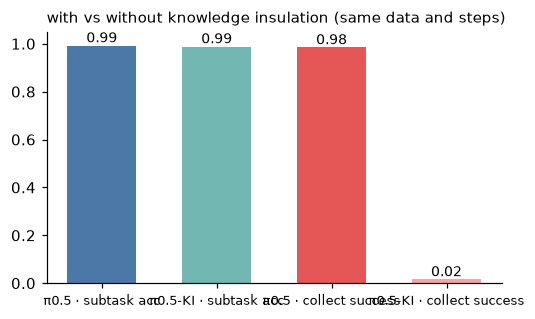

final flow loss: π0.5 0.041 | π0.5-KI 0.183
collect, π0.5   : {'success': 0.984, 'wrong_first': 0.016, 'steps': 25.0, 'path': 1.069}
collect, π0.5-KI: {'success': 0.016, 'wrong_first': 0.219, 'steps': 46.0, 'path': 1.853}


In [14]:
torch.manual_seed(0)
ki_model = copy.deepcopy(pretrained)
ki_model.config.knowledge_insulation = True          # the only difference: stop-gradient into the backbone
ki_hist = PiTrainer(ki_model, data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000)
ki_acc = np.mean([p == t for p, t in zip(ki_model.predict_subtask(tb), tb.subtask)])
r_ki = evaluator.run(lambda b, c: ki_model.act(b), collect)
plots.bar_compare({"π0.5 · subtask acc": acc, "π0.5-KI · subtask acc": ki_acc,
                   "π0.5 · collect success": r_hier.success_rate, "π0.5-KI · collect success": r_ki.success_rate},
                  "", "with vs without knowledge insulation (same data and steps)", ylim=(0, 1.05),
                  colors=["#4c78a8", "#72b7b2", "#e45756", "#f4a6a6"])
print(f"final flow loss: π0.5 {np.mean(history.series('flow')[-50:]):.3f} | π0.5-KI {np.mean(ki_hist.series('flow')[-50:]):.3f}")
print("collect, π0.5   :", r_hier.summary())
print("collect, π0.5-KI:", r_ki.summary())

## Step 10: Recap and exercises

```
image ─────────────────────────────┐
task + discretised state (text) ───┴─► VLM ─► subtask text  (CE)     ← high-level step at run time
                                         └─► FAST tokens     (CE)     ← trains the backbone on actions
                                         │ keys/values  (detach() with KI; FAST hidden from the expert)
noise ε, τ ─► action expert with adaRMS(τ) ─► v_θ ─► Euler ─► chunk   ← low-level step at run time
loss = CE(subtask + FAST) + 10 · flow
```

**What π0.5 added:** language-level reasoning about the next step, a discrete action head that trains the VLM stably, and a recipe for mixing
heterogeneous data. **What it left open** (π0.7): the prompt still only says *what* to do, not *how well* or *how fast*, so suboptimal data
cannot be used safely; there is no memory and no visual goal.

### 🧪 Exercises
1. Set `ordinal_state_init=False` and retrain: how much slower does the model learn without "pre-trained" knowledge of number order?
2. Let the action expert see the FAST tokens (`visible=True` in `Pi05Policy.build_prefix`), train, and compare training flow loss with closed-loop success.
3. Train with `predict_subtask=False` and run `model.act`: what does the high-level step produce now?
4. Change `fast_scale` to 2 and 16 and compare FAST-decoded actions in Step 8.